<a href="https://colab.research.google.com/github/prashantthakur555/Bridgelabz-Training-1Y/blob/main/DataVisualisation_Practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [58]:
import pandas as pd
customers = pd.read_csv("customers.csv")
order_items= pd.read_csv("order_items.csv")
orders = pd.read_csv("orders.csv")
products = pd.read_csv("products.csv")
payments = pd.read_csv("payments.csv")

In [59]:
import matplotlib.pyplot as plt


In [60]:
#1
df_merged = (
    order_items[["order_id", "price"]]
    .merge(orders[["order_id", "customer_id"]], on="order_id")
    .merge(customers[["customer_id", "customer_state"]], on="customer_id")
)
top10_states = (
    df_merged.groupby("customer_state", as_index=False)
    .agg(
        total_item_price=("price", "sum"),
        distinct_orders=("order_id", "nunique"),
    )
    .sort_values("total_item_price", ascending=False)
    .head(10)
)

customer_state  total_item_price  distinct_orders
            SP         5427808.0            16188
            RJ         1669256.0             5079
            MG         1508676.0             4378
            RS          829301.0             2184
            PR          711489.0             1905
            SC          464679.0             1406
            BA          442008.0             1275
            DF          288017.0              844
            GO          276987.0              740
            ES          263805.0              752


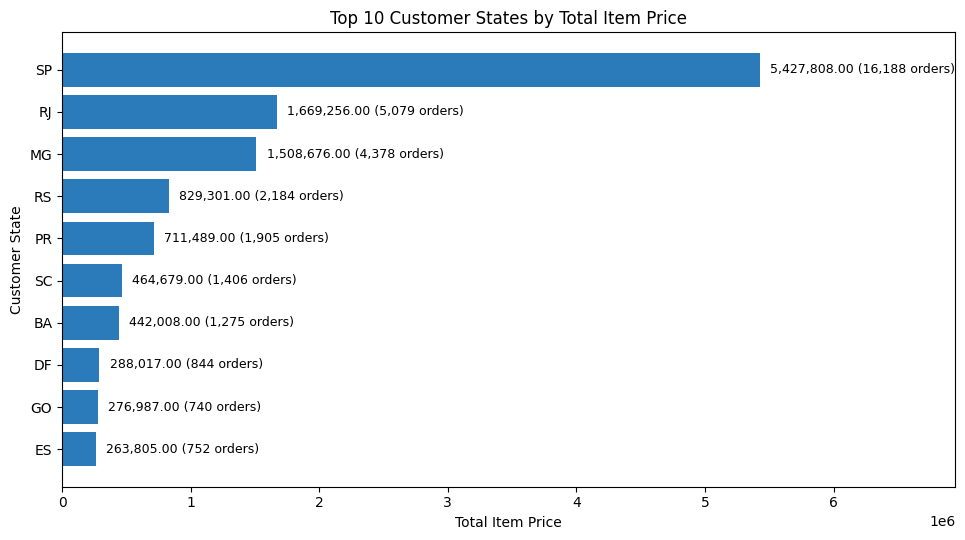

In [61]:
print(top10_states.to_string(index=False))
plot_df = top10_states.iloc[::-1]

plt.figure(figsize=(10, 5.5))
bars = plt.barh(plot_df["customer_state"], plot_df["total_item_price"], color="#2b7bba")

plt.xlabel("Total Item Price")
plt.ylabel("Customer State")
plt.title("Top 10 Customer States by Total Item Price")

max_val = plot_df["total_item_price"].max()
plt.xlim(0, max_val * 1.28)

for bar, (_, row) in zip(bars, plot_df.iterrows()):
    plt.text(
        bar.get_width() + max_val * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{row['total_item_price']:,.2f} ({int(row['distinct_orders']):,} orders)",
        va="center",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

       category  total_item_price
           toys         9795863.0
   garden_tools          413361.0
furniture_decor          340719.0
 bed_bath_table          252201.0
  health_beauty          245294.0
  watches_gifts          243865.0
      telephony          233747.0
 sports_leisure          226183.0


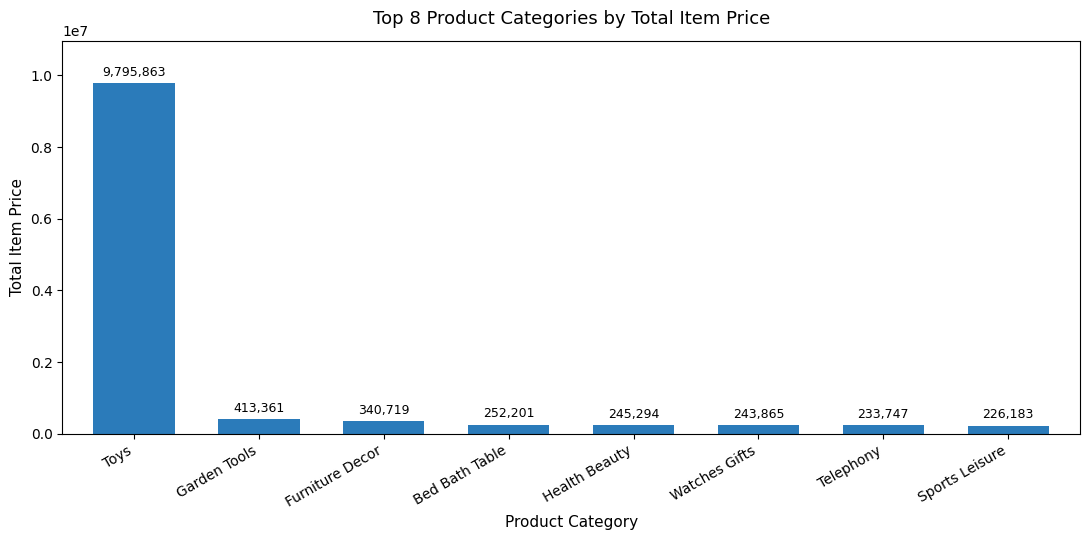

In [62]:
#2
products["category"] = (
    products["product_category_name"]
    .fillna("")
    .astype(str)
    .str.strip()
    .replace("", "Unknown")
)

df_merged = order_items[["product_id", "price"]].merge(
    products[["product_id", "category"]],
    on="product_id",
    how="left",
)
df_merged["category"] = df_merged["category"].fillna("Unknown")

top8_categories = (
    df_merged.groupby("category", as_index=False)["price"]
    .sum()
    .rename(columns={"price": "total_item_price"})
    .sort_values("total_item_price", ascending=False)
    .head(8)
)

top8_categories["display_category"] = (
    top8_categories["category"].str.replace("_", " ").str.title()
)

print(top8_categories[["category", "total_item_price"]].to_string(index=False))

ax = top8_categories.plot(
    kind="bar",
    x="display_category",
    y="total_item_price",
    legend=False,
    figsize=(11, 5.5),
    color="#2b7bba",
    width=0.65,
)

ax.set_title("Top 8 Product Categories by Total Item Price", fontsize=13, pad=12)
ax.set_xlabel("Product Category", fontsize=11)
ax.set_ylabel("Total Item Price", fontsize=11)

plt.xticks(rotation=30, ha="right", fontsize=10)

max_val = top8_categories["total_item_price"].max()
ax.set_ylim(0, max_val * 1.12)
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3, fontsize=9)

plt.tight_layout()
plt.show()

Observation period: 2016-10-03 to 2018-09-03
purchase_month  total_payment_value  is_partial
       2016-10              33233.0        True
       2016-12                352.0       False
       2017-01              92384.0       False
       2017-02             167059.0       False
       2017-03             276610.0       False
       2017-04             259751.0       False
       2017-05             373067.0       False
       2017-06             326921.0       False
       2017-07             430721.0       False
       2017-08             494764.0       False
       2017-09             471612.0       False
       2017-10             485367.0       False
       2017-11             835124.0       False
       2017-12             546592.0       False
       2018-01             760917.0       False
       2018-02             749743.0       False
       2018-03             696831.0       False
       2018-04             715733.0       False
       2018-05             710366.0       F

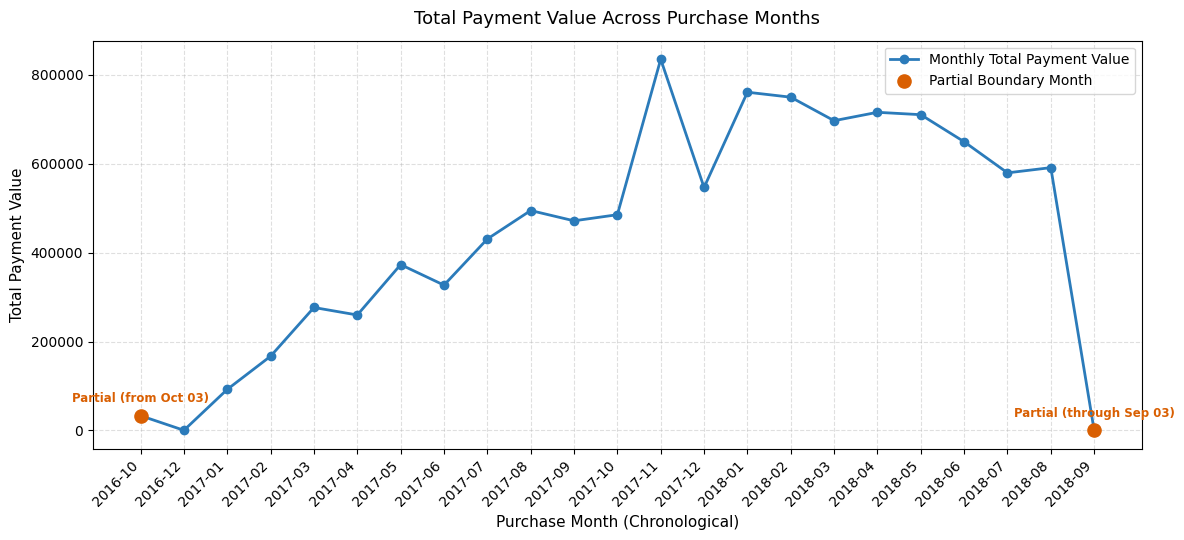

In [63]:
#3
df_merged = payments[["order_id", "payment_value"]].merge(
    orders[["order_id", "order_purchase_timestamp"]].dropna(),
    on="order_id",
)

df_merged["order_purchase_timestamp"] = pd.to_datetime(
    df_merged["order_purchase_timestamp"]
)

min_ts = df_merged["order_purchase_timestamp"].min()
max_ts = df_merged["order_purchase_timestamp"].max()

df_merged["purchase_month"] = df_merged["order_purchase_timestamp"].dt.to_period("M")

monthly_payments = (
    df_merged.groupby("purchase_month", as_index=False)["payment_value"]
    .sum()
    .rename(columns={"payment_value": "total_payment_value"})
    .sort_values("purchase_month")
)

first_month = monthly_payments["purchase_month"].iloc[0]
last_month = monthly_payments["purchase_month"].iloc[-1]

first_is_partial = min_ts.day > 1
last_is_partial = max_ts.day < max_ts.days_in_month

monthly_payments["is_partial"] = False
if first_is_partial:
    monthly_payments.loc[monthly_payments["purchase_month"] == first_month, "is_partial"] = True
if last_is_partial:
    monthly_payments.loc[monthly_payments["purchase_month"] == last_month, "is_partial"] = True

print(f"Observation period: {min_ts.date()} to {max_ts.date()}")
print(monthly_payments.to_string(index=False))

x_labels = monthly_payments["purchase_month"].astype(str)
y_values = monthly_payments["total_payment_value"]

plt.figure(figsize=(12, 5.5))
plt.plot(
    x_labels,
    y_values,
    marker="o",
    linewidth=2,
    markersize=6,
    color="#2b7bba",
    label="Monthly Total Payment Value",
)

partial_rows = monthly_payments[monthly_payments["is_partial"]]
if not partial_rows.empty:
    plt.scatter(
        partial_rows["purchase_month"].astype(str),
        partial_rows["total_payment_value"],
        color="#d95f02",
        s=90,
        zorder=5,
        label="Partial Boundary Month",
    )
    for _, row in partial_rows.iterrows():
        m_str = str(row["purchase_month"])
        note = (
            f"Partial (from {min_ts.strftime('%b %d')})"
            if row["purchase_month"] == first_month
            else f"Partial (through {max_ts.strftime('%b %d')})"
        )
        plt.annotate(
            note,
            (m_str, row["total_payment_value"]),
            textcoords="offset points",
            xytext=(0, 10),
            ha="center",
            fontsize=8.5,
            color="#d95f02",
            fontweight="bold",
        )

plt.title("Total Payment Value Across Purchase Months", fontsize=13, pad=12)
plt.xlabel("Purchase Month (Chronological)", fontsize=11)
plt.ylabel("Total Payment Value", fontsize=11)
plt.xticks(rotation=45, ha="right")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

payment_type    Credit Card  Debit Card  Voucher  Wallet
customer_state                                          
SP                    12021         244      919    3004
RJ                     3824          61      327     867
MG                     3216          50      210     902
RS                     1511          14       92     567
PR                     1382          16       84     423


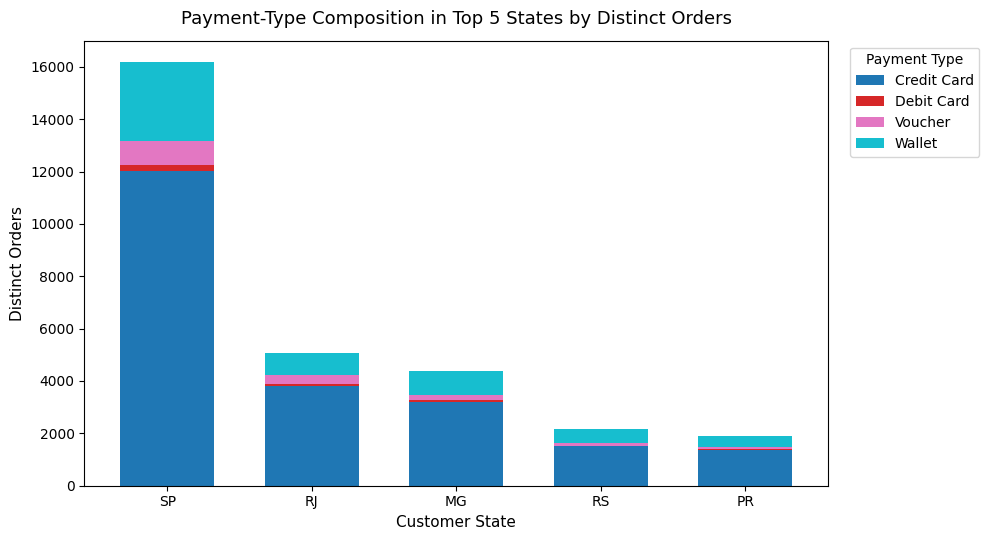

In [64]:
#4
ord_cust = orders[["order_id", "customer_id"]].merge(
    customers[["customer_id", "customer_state"]], on="customer_id"
)

top5_states = (
    ord_cust.groupby("customer_state")["order_id"]
    .nunique()
    .nlargest(5)
    .index.tolist()
)

df_merged = ord_cust[ord_cust["customer_state"].isin(top5_states)].merge(
    payments[["order_id", "payment_type"]], on="order_id"
)
df_merged["payment_type"] = (
    df_merged["payment_type"]
    .fillna("Unknown")
    .str.replace("_", " ")
    .str.title()
)

piv_payment = (
    df_merged.groupby(["customer_state", "payment_type"])["order_id"]
    .nunique()
    .unstack(fill_value=0)
    .loc[top5_states]
)

print(piv_payment)

ax = piv_payment.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5.5),
    width=0.65,
    colormap="tab10",
)

ax.set_title("Payment-Type Composition in Top 5 States by Distinct Orders", fontsize=13, pad=12)
ax.set_xlabel("Customer State", fontsize=11)
ax.set_ylabel("Distinct Orders", fontsize=11)
plt.xticks(rotation=0, fontsize=10)
plt.legend(title="Payment Type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

             category  distinct_orders  mean_item_price  mean_shipping_charges
                 toys            28697       341.354950              44.696205
        health_beauty             1038       236.314066              41.968208
       bed_bath_table              948       266.034810              42.280591
       sports_leisure              804       281.322139              43.064677
computers_accessories              746       272.540214              41.903485
      furniture_decor              744       457.955645              43.958333
           housewares              586       289.984642              42.943686
        watches_gifts              489       498.701431              42.112474


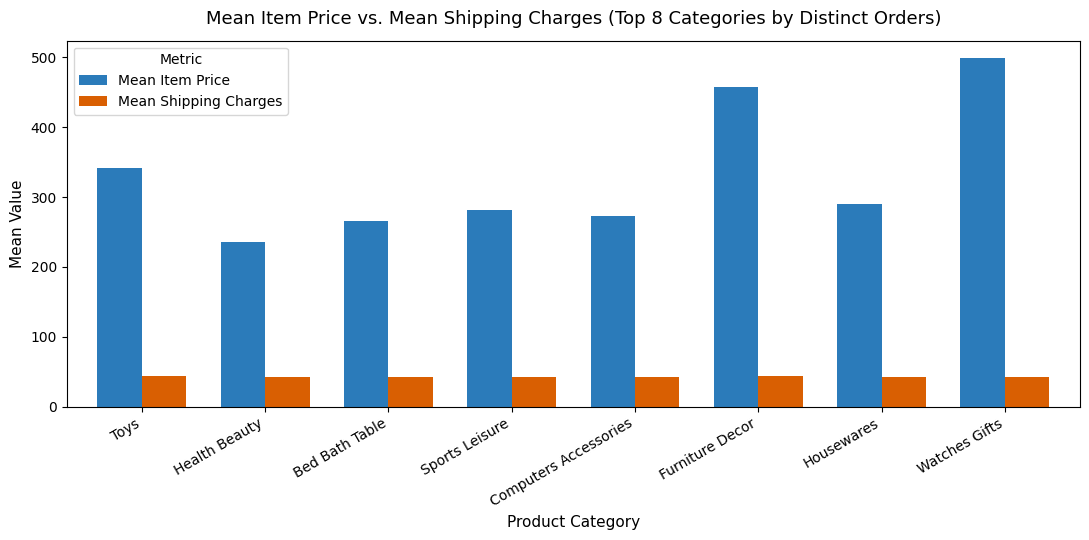

In [65]:
#5
products["category"] = (
    products["product_category_name"]
    .fillna("")
    .astype(str)
    .str.strip()
    .replace("", "Unknown")
)

df_merged = order_items[["order_id", "product_id", "price", "shipping_charges"]].merge(
    products[["product_id", "category"]],
    on="product_id",
    how="left",
)
df_merged["category"] = df_merged["category"].fillna("Unknown")

top8_order_cats = (
    df_merged.groupby("category", as_index=False)
    .agg(
        distinct_orders=("order_id", "nunique"),
        mean_item_price=("price", "mean"),
        mean_shipping_charges=("shipping_charges", "mean"),
    )
    .sort_values("distinct_orders", ascending=False)
    .head(8)
)

top8_order_cats["display_category"] = (
    top8_order_cats["category"].str.replace("_", " ").str.title()
)

print(
    top8_order_cats[
        ["category", "distinct_orders", "mean_item_price", "mean_shipping_charges"]
    ].to_string(index=False)
)

ax = top8_order_cats.set_index("display_category")[
    ["mean_item_price", "mean_shipping_charges"]
].plot(
    kind="bar",
    figsize=(11, 5.5),
    width=0.72,
    color=["#2b7bba", "#d95f02"],
)

ax.set_title(
    "Mean Item Price vs. Mean Shipping Charges (Top 8 Categories by Distinct Orders)",
    fontsize=13,
    pad=12,
)
ax.set_xlabel("Product Category", fontsize=11)
ax.set_ylabel("Mean Value", fontsize=11)
ax.legend(["Mean Item Price", "Mean Shipping Charges"], title="Metric")

plt.xticks(rotation=30, ha="right", fontsize=10)
plt.tight_layout()
plt.show()

customer_state    SP   RJ   MG   RS
purchase_hour                      
0                407  138   83   70
1                202   80   47   21
2                 97   39   16   10
3                 46   20   10    8
4                 44   11    6    7
5                 34   19    5   13
6                 76   19   19    6
7                192   64   57   11
8                471  116  148   54
9                716  237  216  132
10              1053  297  266  112
11              1022  312  298  114
12              1038  332  266  115
13              1107  297  307  135
14              1072  361  312  167
15              1065  334  269  126
16              1075  349  305  147
17              1006  304  282  137
18               921  324  244  102
19               915  325  260  135
20               990  297  264  162
21               944  300  271  137
22               983  269  247  154
23               712  235  180  109


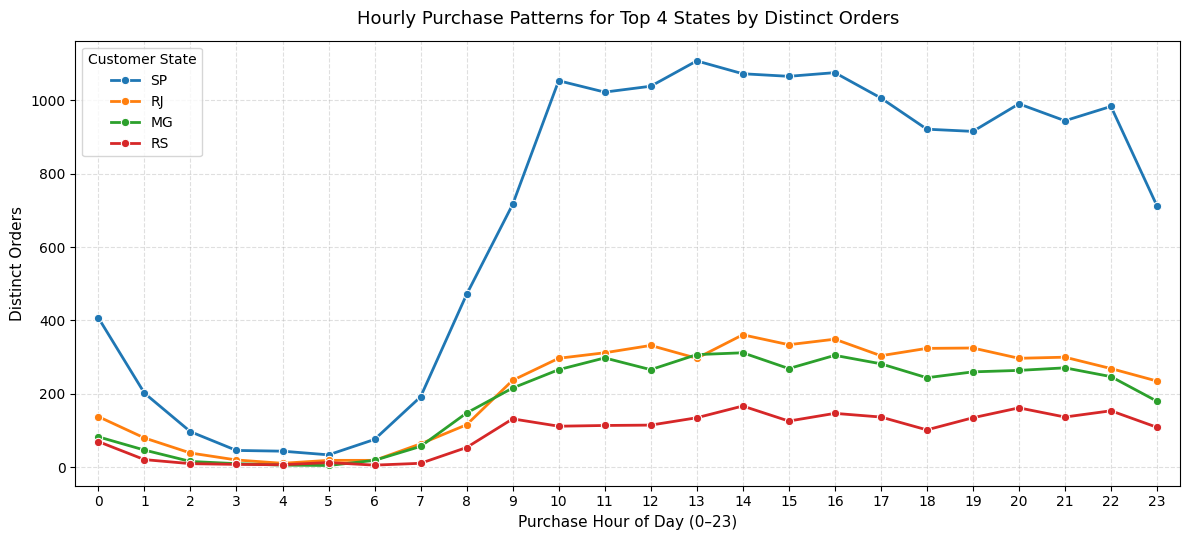

In [66]:
#6
import seaborn as sns

ord_cust = orders.dropna(subset=["order_purchase_timestamp"]).merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
)
ord_cust["order_purchase_timestamp"] = pd.to_datetime(
    ord_cust["order_purchase_timestamp"]
)

top4_states = (
    ord_cust.groupby("customer_state")["order_id"]
    .nunique()
    .nlargest(4)
    .index.tolist()
)

sub = ord_cust[ord_cust["customer_state"].isin(top4_states)].copy()
sub["purchase_hour"] = sub["order_purchase_timestamp"].dt.hour

hourly_counts = (
    sub.groupby(["customer_state", "purchase_hour"], as_index=False)["order_id"]
    .nunique()
    .rename(columns={"order_id": "distinct_orders"})
)

full_grid = pd.MultiIndex.from_product(
    [top4_states, range(24)],
    names=["customer_state", "purchase_hour"],
).to_frame(index=False)

hourly_full = full_grid.merge(
    hourly_counts,
    on=["customer_state", "purchase_hour"],
    how="left",
).fillna({"distinct_orders": 0})

hourly_full["distinct_orders"] = hourly_full["distinct_orders"].astype(int)

print(
    hourly_full.pivot(
        index="purchase_hour",
        columns="customer_state",
        values="distinct_orders",
    )[top4_states]
)

plt.figure(figsize=(12, 5.5))
sns.lineplot(
    data=hourly_full,
    x="purchase_hour",
    y="distinct_orders",
    hue="customer_state",
    hue_order=top4_states,
    marker="o",
    linewidth=2,
)

plt.xticks(range(0, 24))
plt.xlim(-0.5, 23.5)
plt.xlabel("Purchase Hour of Day (0–23)", fontsize=11)
plt.ylabel("Distinct Orders", fontsize=11)
plt.title("Hourly Purchase Patterns for Top 4 States by Distinct Orders", fontsize=13, pad=12)
plt.legend(title="Customer State")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Distinct customers with items: 38,279
Max orders per customer_id: 1
count    38279.000000
mean       342.533295
std        560.289323
min          1.000000
25%         60.000000
50%        137.000000
75%        399.000000
90%        820.000000
95%       1186.300000
99%       2899.000000
max       6729.000000
Name: total_item_price, dtype: float64


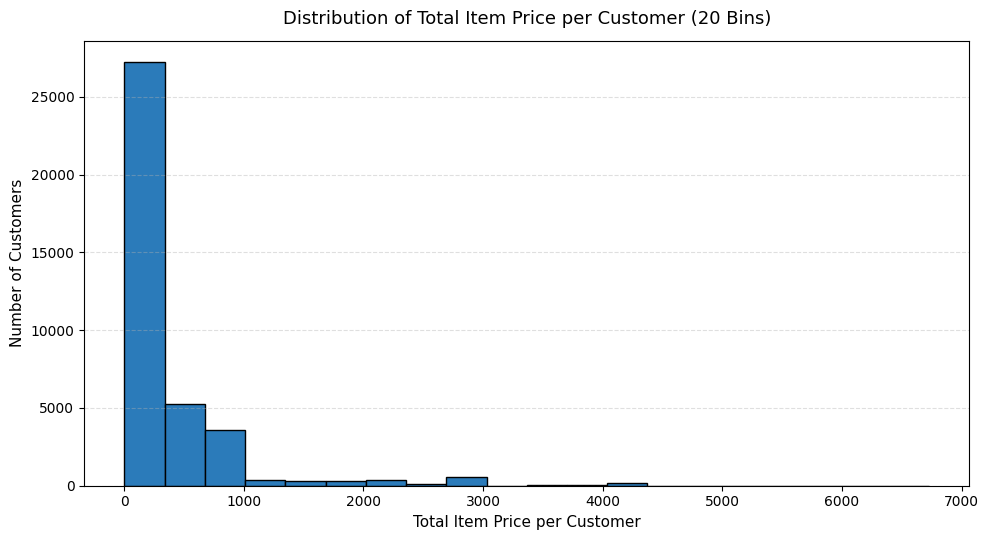

In [67]:
#7
cust_totals = (
    orders[["order_id", "customer_id"]]
    .merge(order_items[["order_id", "price"]], on="order_id")
    .groupby("customer_id", as_index=False)["price"]
    .sum()
    .rename(columns={"price": "total_item_price"})
)

orders_per_cust = orders.groupby("customer_id")["order_id"].nunique()
print(f"Distinct customers with items: {len(cust_totals):,}")
print(f"Max orders per customer_id: {orders_per_cust.max()}")
print(
    cust_totals["total_item_price"].describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
    )
)

plt.figure(figsize=(10, 5.5))
plt.hist(
    cust_totals["total_item_price"],
    bins=20,
    color="#2b7bba",
    edgecolor="black",
)
plt.xlabel("Total Item Price per Customer", fontsize=11)
plt.ylabel("Number of Customers", fontsize=11)
plt.title("Distribution of Total Item Price per Customer (20 Bins)", fontsize=13, pad=12)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

customer_state  order_count  total_payment_value
            SP        16188            4246676.0
            RJ         5079            1389567.0
            MG         4378            1213314.0
            RS         2184             589925.0
            PR         1905             501098.0
            SC         1406             378775.0
            BA         1275             326927.0
            DF          844             236486.0
            GO          740             204962.0
            ES          752             190462.0
            PE          605             148416.0
            CE          472             143087.0
            PA          361              95618.0
            MA          302              93497.0
            MT          354              90795.0
            MS          261              64594.0
            RN          213              62611.0
            PB          195              55062.0
            PI          183              51278.0
            AL      

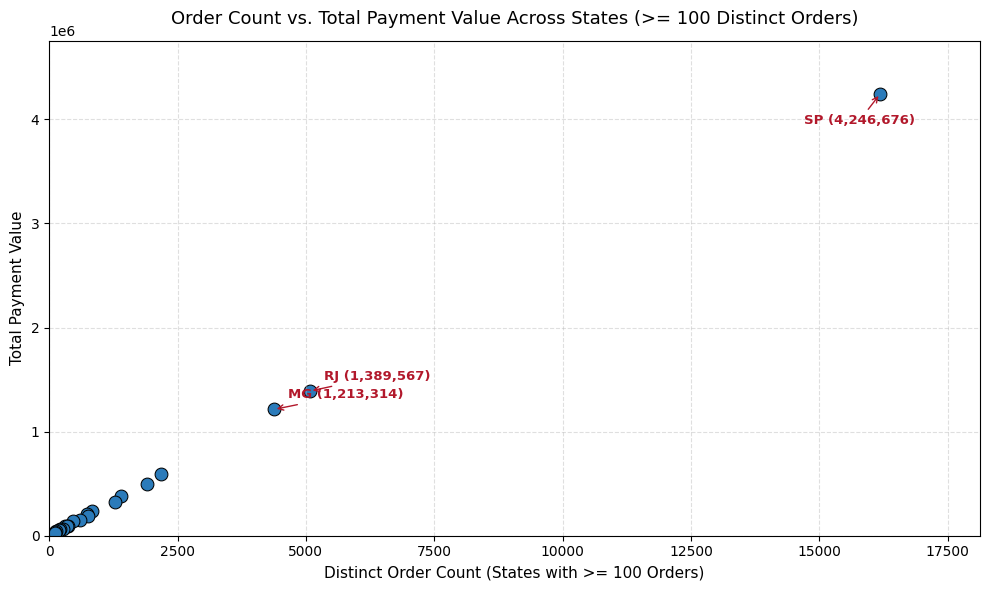

In [68]:
#8
cust_orders = customers[["customer_id", "customer_state"]].merge(
    orders[["order_id", "customer_id"]],
    on="customer_id",
)

order_counts = (
    cust_orders.groupby("customer_state", as_index=False)["order_id"]
    .nunique()
    .rename(columns={"order_id": "order_count"})
)

pay_totals = (
    cust_orders[["customer_state", "order_id"]]
    .drop_duplicates()
    .merge(payments[["order_id", "payment_value"]], on="order_id")
    .groupby("customer_state", as_index=False)["payment_value"]
    .sum()
    .rename(columns={"payment_value": "total_payment_value"})
)

state_df = (
    order_counts.merge(pay_totals, on="customer_state", how="left")
    .fillna({"total_payment_value": 0.0})
    .query("order_count >= 100")
    .sort_values("total_payment_value", ascending=False)
    .reset_index(drop=True)
)

print(state_df.to_string(index=False))

top3_states = state_df.head(3)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=state_df,
    x="order_count",
    y="total_payment_value",
    s=85,
    color="#2b7bba",
    edgecolor="black",
)

x_max = state_df["order_count"].max()
y_max = state_df["total_payment_value"].max()

for idx, (_, row) in enumerate(top3_states.iterrows()):
    x_offset = -55 if idx == 0 else 10
    y_offset = -22 if idx == 0 else 8
    plt.annotate(
        f"{row['customer_state']} ({row['total_payment_value']:,.0f})",
        xy=(row["order_count"], row["total_payment_value"]),
        xytext=(x_offset, y_offset),
        textcoords="offset points",
        fontsize=9.5,
        fontweight="bold",
        color="#b2182b",
        arrowprops=dict(arrowstyle="->", color="#b2182b", lw=1),
    )

plt.xlabel("Distinct Order Count (States with >= 100 Orders)", fontsize=11)
plt.ylabel("Total Payment Value", fontsize=11)
plt.title(
    "Order Count vs. Total Payment Value Across States (>= 100 Distinct Orders)",
    fontsize=13,
    pad=12,
)
plt.xlim(0, x_max * 1.12)
plt.ylim(0, y_max * 1.12)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

                 plotted_products  median     q25    q75        mean
category                                                            
toys                        12469   146.0  67.000  390.0  312.482318
bed_bath_table                429   127.0  62.000  319.0  285.985374
sports_leisure                361   165.0  83.000  349.0  308.644403
furniture_decor               351   189.0  89.125  518.0  421.273117
health_beauty                 325   151.0  68.000  390.0  307.269455
housewares                    319   135.0  62.625  364.5  270.755267


/tmp/ipykernel_995/2746514871.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


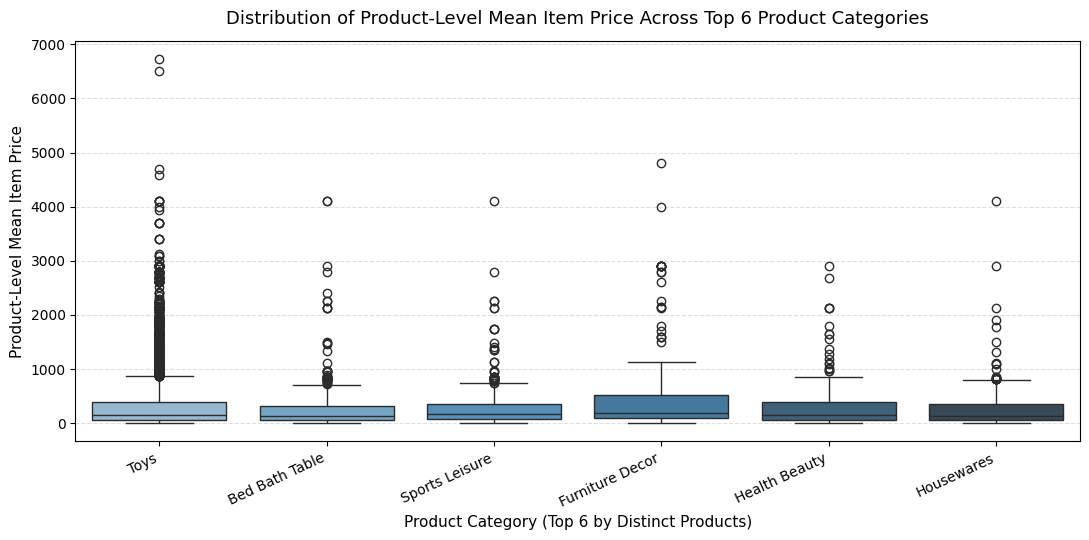

In [69]:
#9
products["category"] = (
    products["product_category_name"]
    .fillna("")
    .astype(str)
    .str.strip()
    .replace("", "Unknown")
)

top6_cats = (
    products.groupby("category")["product_id"]
    .nunique()
    .nlargest(6)
    .index.tolist()
)

prod_mean_prices = (
    order_items.groupby("product_id", as_index=False)["price"]
    .mean()
    .rename(columns={"price": "mean_item_price"})
    .merge(products[["product_id", "category"]], on="product_id", how="inner")
)

plot_df = prod_mean_prices[prod_mean_prices["category"].isin(top6_cats)].copy()
plot_df["display_category"] = plot_df["category"].str.replace("_", " ").str.title()
display_order = [c.replace("_", " ").title() for c in top6_cats]

summary_stats = (
    plot_df.groupby("category")["mean_item_price"]
    .agg(
        plotted_products="count",
        median="median",
        q25=lambda s: s.quantile(0.25),
        q75=lambda s: s.quantile(0.75),
        mean="mean",
    )
    .loc[top6_cats]
)
print(summary_stats)

plt.figure(figsize=(11, 5.5))
sns.boxplot(
    data=plot_df,
    x="display_category",
    y="mean_item_price",
    order=display_order,
    palette="Blues_d",
)

plt.xlabel("Product Category (Top 6 by Distinct Products)", fontsize=11)
plt.ylabel("Product-Level Mean Item Price", fontsize=11)
plt.title(
    "Distribution of Product-Level Mean Item Price Across Top 6 Product Categories",
    fontsize=13,
    pad=12,
)
plt.xticks(rotation=25, ha="right", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

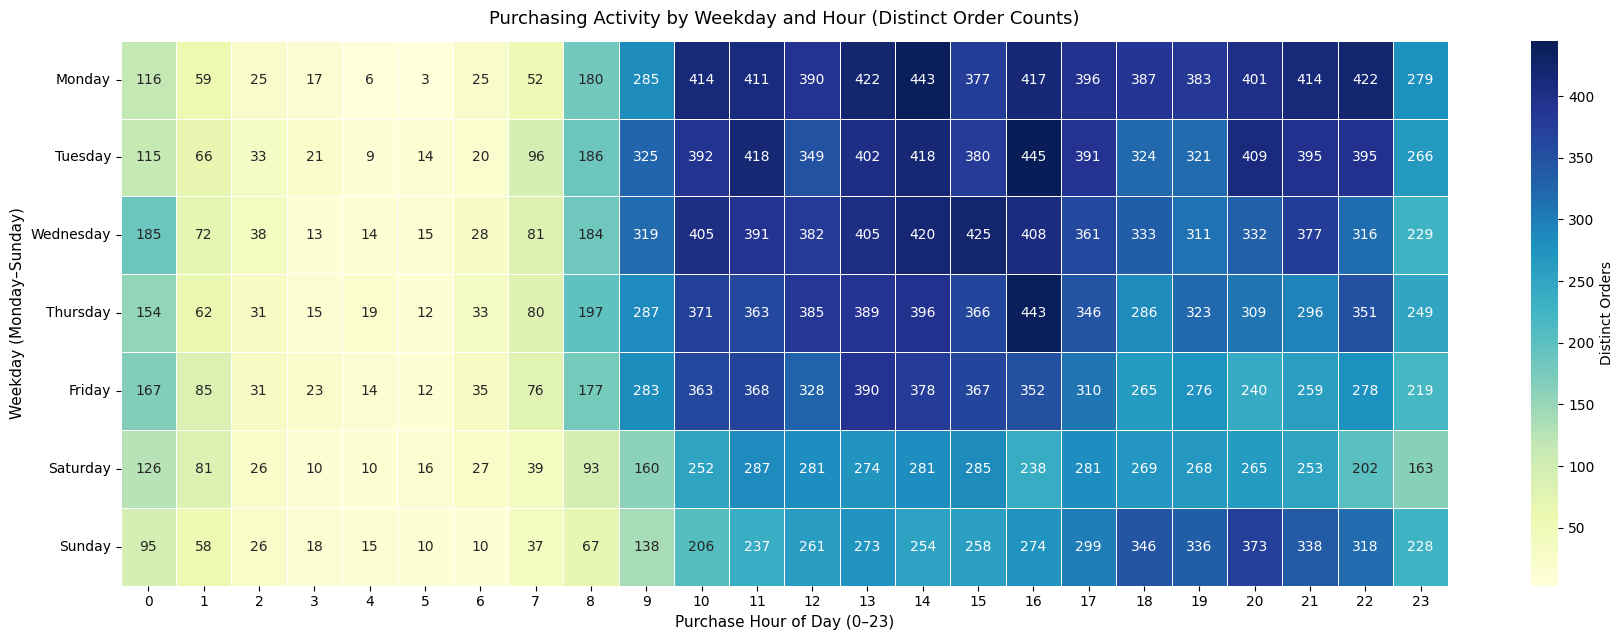

In [70]:
#10
df_orders = orders.dropna(subset=["order_purchase_timestamp"]).copy()
df_orders["purchase_dt"] = pd.to_datetime(df_orders["order_purchase_timestamp"])
df_orders["weekday"] = df_orders["purchase_dt"].dt.day_name()
df_orders["hour"] = df_orders["purchase_dt"].dt.hour

weekdays = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]
hours = list(range(24))

heatmap_df = (
    df_orders.groupby(["weekday", "hour"])["order_id"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(index=weekdays, columns=hours, fill_value=0)
)

plt.figure(figsize=(18, 6.5))
ax = sns.heatmap(
    heatmap_df,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.4,
    linecolor="white",
    cbar_kws={"label": "Distinct Orders"},
)
ax.set_title(
    "Purchasing Activity by Weekday and Hour (Distinct Order Counts)",
    fontsize=13,
    pad=12,
)
ax.set_xlabel("Purchase Hour of Day (0–23)", fontsize=11)
ax.set_ylabel("Weekday (Monday–Sunday)", fontsize=11)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

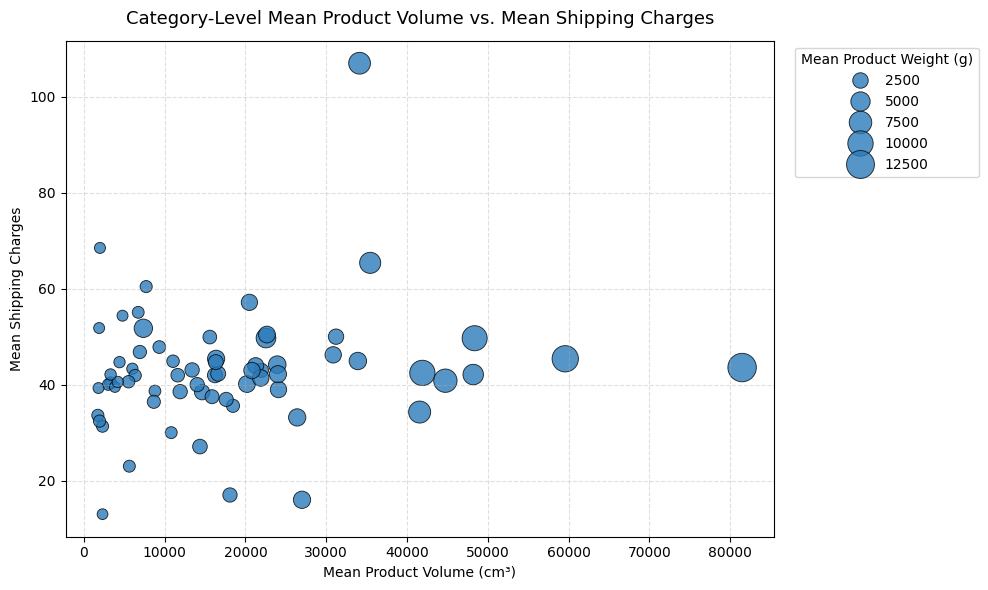

In [71]:
#11
prod_clean = products.copy()
prod_clean["category"] = (
    prod_clean["product_category_name"]
    .fillna("")
    .astype(str)
    .str.strip()
    .replace("", "Unknown")
)

dim_cols = ["product_length_cm", "product_height_cm", "product_width_cm"]
weight_col = "product_weight_g"

prod_clean = prod_clean.dropna(subset=dim_cols + [weight_col]).copy()
prod_clean["product_volume"] = (
    prod_clean["product_length_cm"]
    * prod_clean["product_height_cm"]
    * prod_clean["product_width_cm"]
)

prod_valid = prod_clean[
    (prod_clean["product_volume"] > 0) & (prod_clean[weight_col] > 0)
].copy()

prod_metrics = (
    prod_valid.groupby("category", as_index=False)
    .agg(
        mean_product_volume=("product_volume", "mean"),
        mean_product_weight=(weight_col, "mean"),
    )
)

ship_metrics = (
    order_items[["product_id", "shipping_charges"]]
    .dropna(subset=["shipping_charges"])
    .merge(prod_valid[["product_id", "category"]], on="product_id", how="inner")
    .groupby("category", as_index=False)
    .agg(mean_shipping_charges=("shipping_charges", "mean"))
)

cat_summary = prod_metrics.merge(ship_metrics, on="category", how="inner")

plt.figure(figsize=(10, 6))
ax = sns.scatterplot(
    data=cat_summary,
    x="mean_product_volume",
    y="mean_shipping_charges",
    size="mean_product_weight",
    sizes=(60, 420),
    alpha=0.8,
    color="#2b7bba",
    edgecolor="black",
)
ax.set_title(
    "Category-Level Mean Product Volume vs. Mean Shipping Charges",
    fontsize=13,
    pad=12,
)
ax.set_xlabel("Mean Product Volume (cm³)")
ax.set_ylabel("Mean Shipping Charges")
plt.legend(title="Mean Product Weight (g)", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Observed periods by purchase year:
 purchase_year  total_payment            min_date            max_date  active_months
          2018      5453883.0 2018-01-01 02:48:41 2018-09-03 09:06:57              9
          2017      4759972.0 2017-01-05 12:01:20 2017-12-31 21:10:02             12
          2016        33585.0 2016-10-03 16:56:50 2016-12-23 23:16:47              2


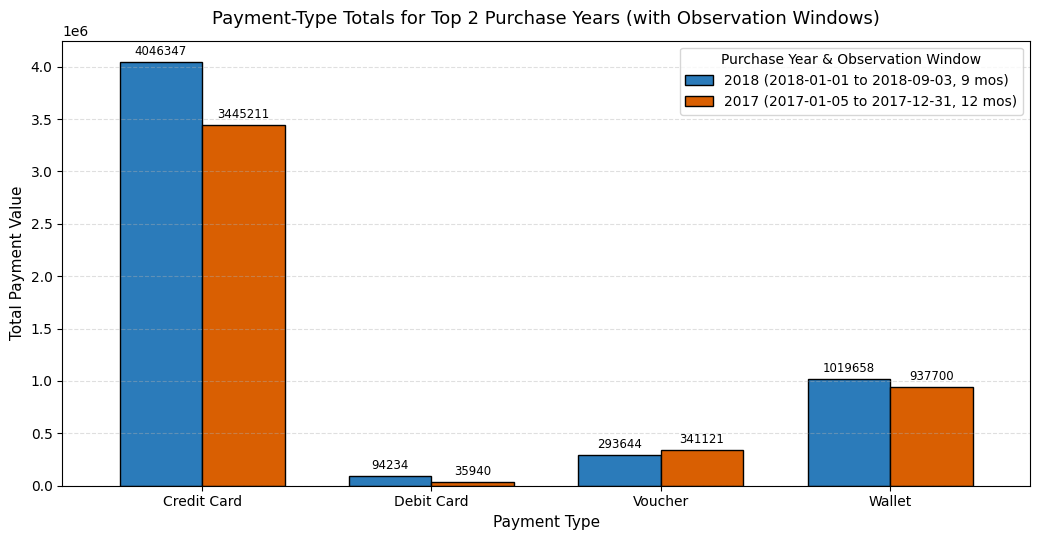

In [72]:
#12
df_pay = payments[["order_id", "payment_type", "payment_value"]].merge(
    orders[["order_id", "order_purchase_timestamp"]].dropna(
        subset=["order_purchase_timestamp"]
    ),
    on="order_id",
    how="inner",
)
df_pay["purchase_dt"] = pd.to_datetime(df_pay["order_purchase_timestamp"])
df_pay["purchase_year"] = df_pay["purchase_dt"].dt.year
df_pay["purchase_ym"] = df_pay["purchase_dt"].dt.to_period("M")
df_pay["payment_type"] = (
    df_pay["payment_type"].fillna("Unknown").str.replace("_", " ").str.title()
)

year_periods = (
    df_pay.groupby("purchase_year", as_index=False)
    .agg(
        total_payment=("payment_value", "sum"),
        min_date=("purchase_dt", "min"),
        max_date=("purchase_dt", "max"),
        active_months=("purchase_ym", "nunique"),
    )
    .sort_values("total_payment", ascending=False)
)

top2_years = year_periods["purchase_year"].head(2).tolist()
period_labels = {
    int(row["purchase_year"]): (
        f"{int(row['purchase_year'])} "
        f"({row['min_date'].strftime('%Y-%m-%d')} to {row['max_date'].strftime('%Y-%m-%d')}, "
        f"{int(row['active_months'])} mos)"
    )
    for _, row in year_periods.iterrows()
}

print("Observed periods by purchase year:")
print(year_periods.to_string(index=False))

piv_top2 = (
    df_pay[df_pay["purchase_year"].isin(top2_years)]
    .groupby(["payment_type", "purchase_year"])["payment_value"]
    .sum()
    .unstack(fill_value=0)
    .reindex(columns=top2_years, fill_value=0)
    .rename(columns=period_labels)
)

ax = piv_top2.plot(
    kind="bar",
    figsize=(10.5, 5.5),
    width=0.72,
    color=["#2b7bba", "#d95f02"],
    edgecolor="black",
)
ax.set_title(
    "Payment-Type Totals for Top 2 Purchase Years (with Observation Windows)",
    fontsize=13,
    pad=12,
)
ax.set_xlabel("Payment Type", fontsize=11)
ax.set_ylabel("Total Payment Value", fontsize=11)
plt.xticks(rotation=0, fontsize=10)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3, fontsize=8.5)
plt.legend(title="Purchase Year & Observation Window")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

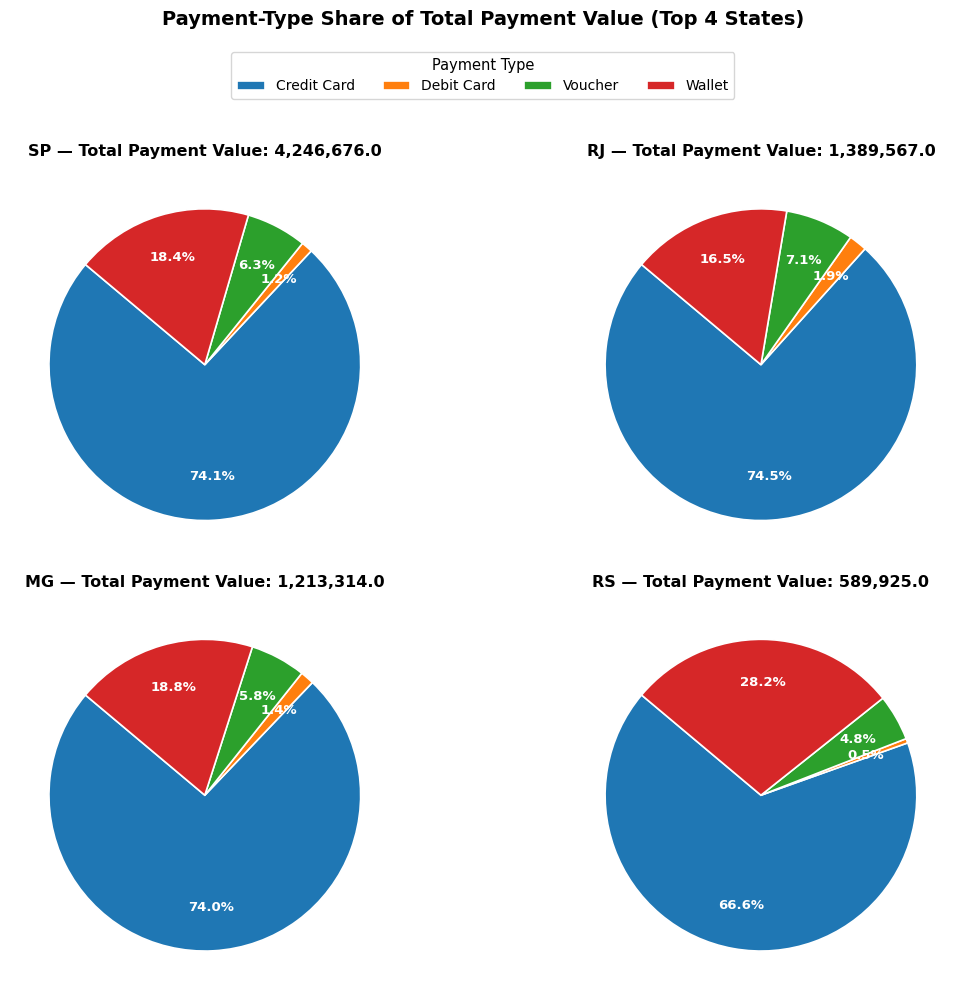

In [73]:
#13
cust_orders = orders[["order_id", "customer_id"]].merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="inner",
)

pay_by_state = (
    cust_orders[["customer_state", "order_id"]]
    .drop_duplicates()
    .merge(
        payments[["order_id", "payment_type", "payment_value"]],
        on="order_id",
        how="inner",
    )
)
pay_by_state["payment_type"] = (
    pay_by_state["payment_type"].fillna("Unknown").str.replace("_", " ").str.title()
)

top4_states = (
    pay_by_state.groupby("customer_state")["payment_value"]
    .sum()
    .nlargest(4)
    .index.tolist()
)

state_totals = (
    pay_by_state[pay_by_state["customer_state"].isin(top4_states)]
    .groupby("customer_state")["payment_value"]
    .sum()
    .loc[top4_states]
)

piv_val = (
    pay_by_state[pay_by_state["customer_state"].isin(top4_states)]
    .groupby(["payment_type", "customer_state"])["payment_value"]
    .sum()
    .unstack(fill_value=0)
    .reindex(columns=top4_states, fill_value=0)
)

all_types = piv_val.index.tolist()
palette = plt.cm.tab10.colors
color_map = {ptype: palette[i % len(palette)] for i, ptype in enumerate(all_types)}
colors = [color_map[ptype] for ptype in all_types]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, st in zip(axes, top4_states):
    st_series = piv_val[st]
    ax.pie(
        st_series,
        labels=None,
        autopct="%1.1f%%",
        startangle=140,
        colors=colors,
        pctdistance=0.72,
        wedgeprops={"edgecolor": "white", "linewidth": 1.2},
        textprops={"fontsize": 9.5, "color": "white", "weight": "bold"},
    )
    ax.set_title(
        f"{st} — Total Payment Value: {state_totals[st]:,.1f}",
        fontsize=11.5,
        fontweight="bold",
        pad=10,
    )

fig.legend(
    all_types,
    title="Payment Type",
    loc="upper center",
    ncol=min(len(all_types), 4),
    bbox_to_anchor=(0.5, 0.96),
    frameon=True,
    fontsize=10,
    title_fontsize=10.5,
)
fig.suptitle(
    "Payment-Type Share of Total Payment Value (Top 4 States)",
    fontsize=14,
    fontweight="bold",
    y=0.995,
)
plt.tight_layout(rect=[0, 0, 1, 0.91])
plt.show()

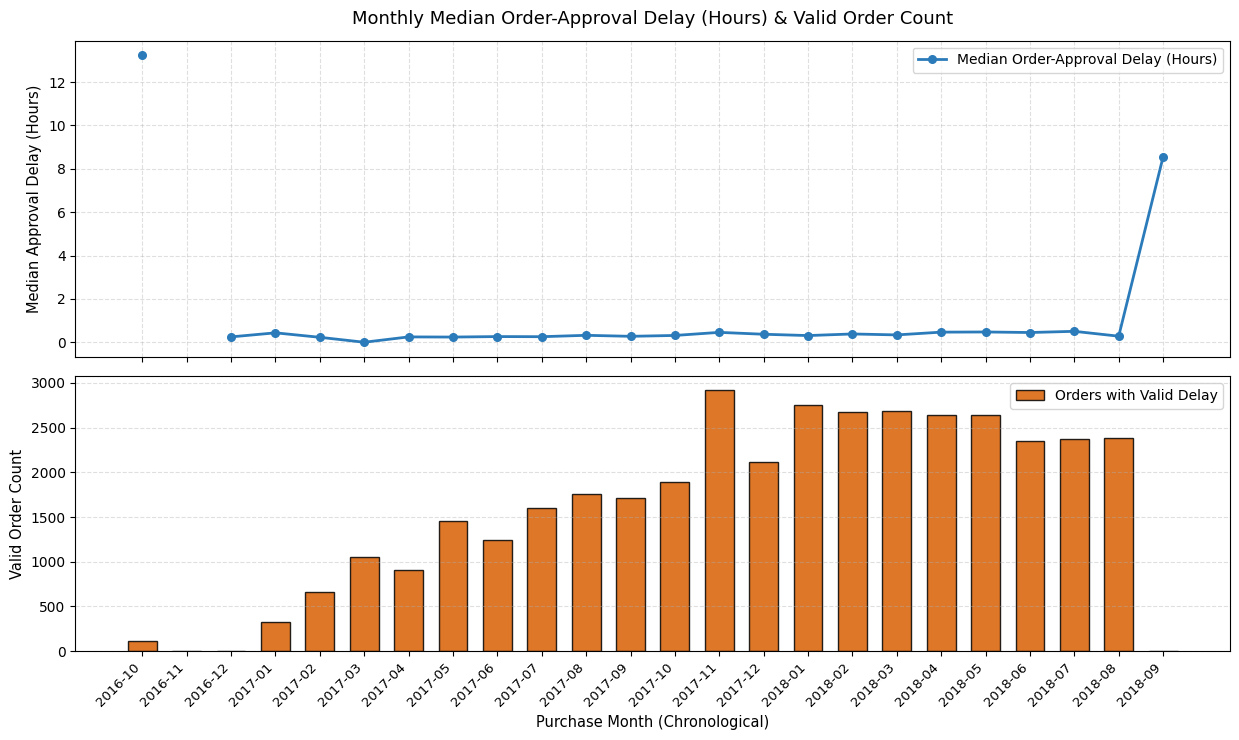

In [74]:
#14
df_delay = orders[["order_id", "order_purchase_timestamp", "order_approved_at"]].copy()
df_delay = df_delay.dropna(subset=["order_purchase_timestamp", "order_approved_at"])

df_delay["purchase_dt"] = pd.to_datetime(df_delay["order_purchase_timestamp"])
df_delay["approved_dt"] = pd.to_datetime(df_delay["order_approved_at"])

df_delay["approval_delay_hours"] = (
    df_delay["approved_dt"] - df_delay["purchase_dt"]
).dt.total_seconds() / 3600.0

df_valid = df_delay[df_delay["approval_delay_hours"] >= 0].copy()
df_valid["purchase_month"] = df_valid["purchase_dt"].dt.to_period("M")

monthly_summary = (
    df_valid.groupby("purchase_month", as_index=False)
    .agg(
        median_approval_delay_hours=("approval_delay_hours", "median"),
        valid_order_count=("order_id", "nunique"),
    )
    .sort_values("purchase_month")
)

all_months = pd.period_range(
    monthly_summary["purchase_month"].min(),
    monthly_summary["purchase_month"].max(),
    freq="M",
)
monthly_summary = (
    monthly_summary.set_index("purchase_month")
    .reindex(all_months)
    .assign(valid_order_count=lambda d: d["valid_order_count"].fillna(0).astype(int))
    .reset_index()
    .rename(columns={"index": "purchase_month"})
)

x_labels = monthly_summary["purchase_month"].astype(str)

fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, sharex=True, figsize=(12.5, 7.5), gridspec_kw={"height_ratios": [1.15, 1]}
)

ax_top.plot(
    x_labels,
    monthly_summary["median_approval_delay_hours"],
    marker="o",
    linewidth=2,
    markersize=5.5,
    color="#2b7bba",
    label="Median Order-Approval Delay (Hours)",
)
ax_top.set_ylabel("Median Approval Delay (Hours)", fontsize=10.5)
ax_top.set_title(
    "Monthly Median Order-Approval Delay (Hours) & Valid Order Count",
    fontsize=13,
    pad=12,
)
ax_top.grid(True, linestyle="--", alpha=0.4)
ax_top.legend(loc="upper right")

ax_bot.bar(
    x_labels,
    monthly_summary["valid_order_count"],
    color="#d95f02",
    width=0.65,
    edgecolor="black",
    alpha=0.85,
    label="Orders with Valid Delay",
)
ax_bot.set_xlabel("Purchase Month (Chronological)", fontsize=10.5)
ax_bot.set_ylabel("Valid Order Count", fontsize=10.5)
ax_bot.grid(axis="y", linestyle="--", alpha=0.4)
ax_bot.legend(loc="upper right")

plt.xticks(rotation=45, ha="right", fontsize=9.5)
plt.tight_layout()
plt.show()

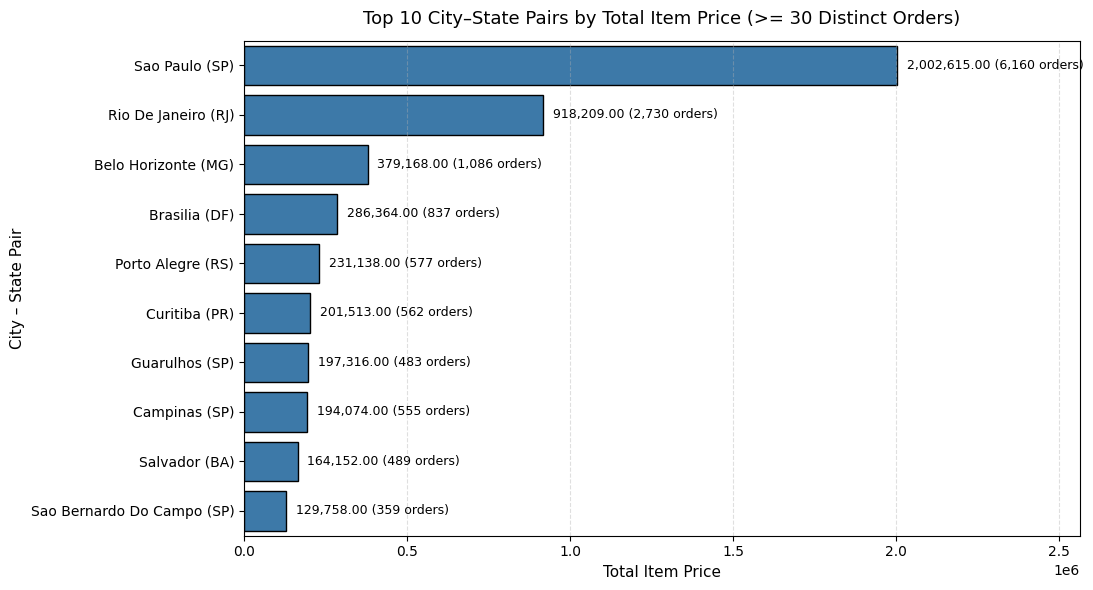

In [75]:
#15
df_city_state = (
    order_items[["order_id", "price"]]
    .merge(orders[["order_id", "customer_id"]], on="order_id", how="inner")
    .merge(
        customers[["customer_id", "customer_city", "customer_state"]],
        on="customer_id",
        how="inner",
    )
    .dropna(subset=["customer_city", "customer_state"])
    .copy()
)

df_city_state["customer_city"] = df_city_state["customer_city"].astype(str).str.strip()
df_city_state["customer_state"] = df_city_state["customer_state"].astype(str).str.strip()

city_state_summary = (
    df_city_state.groupby(["customer_city", "customer_state"], as_index=False)
    .agg(
        total_item_price=("price", "sum"),
        distinct_orders=("order_id", "nunique"),
    )
    .query("distinct_orders >= 30")
    .sort_values("total_item_price", ascending=False)
    .head(10)
    .copy()
)

city_state_summary["city_state_label"] = (
    city_state_summary["customer_city"].str.replace("_", " ").str.title()
    + " ("
    + city_state_summary["customer_state"]
    + ")"
)

plt.figure(figsize=(11, 6))
ax = sns.barplot(
    data=city_state_summary,
    x="total_item_price",
    y="city_state_label",
    color="#2b7bba",
    edgecolor="black",
)
max_val = city_state_summary["total_item_price"].max()
ax.set_xlim(0, max_val * 1.28)
ax.set_xlabel("Total Item Price", fontsize=11)
ax.set_ylabel("City – State Pair", fontsize=11)
ax.set_title(
    "Top 10 City–State Pairs by Total Item Price (>= 30 Distinct Orders)",
    fontsize=13,
    pad=12,
)
for p, (_, row) in zip(ax.patches, city_state_summary.iterrows()):
    ax.text(
        p.get_width() + max_val * 0.015,
        p.get_y() + p.get_height() / 2,
        f"{row['total_item_price']:,.2f} ({int(row['distinct_orders']):,} orders)",
        va="center",
        fontsize=9,
    )
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

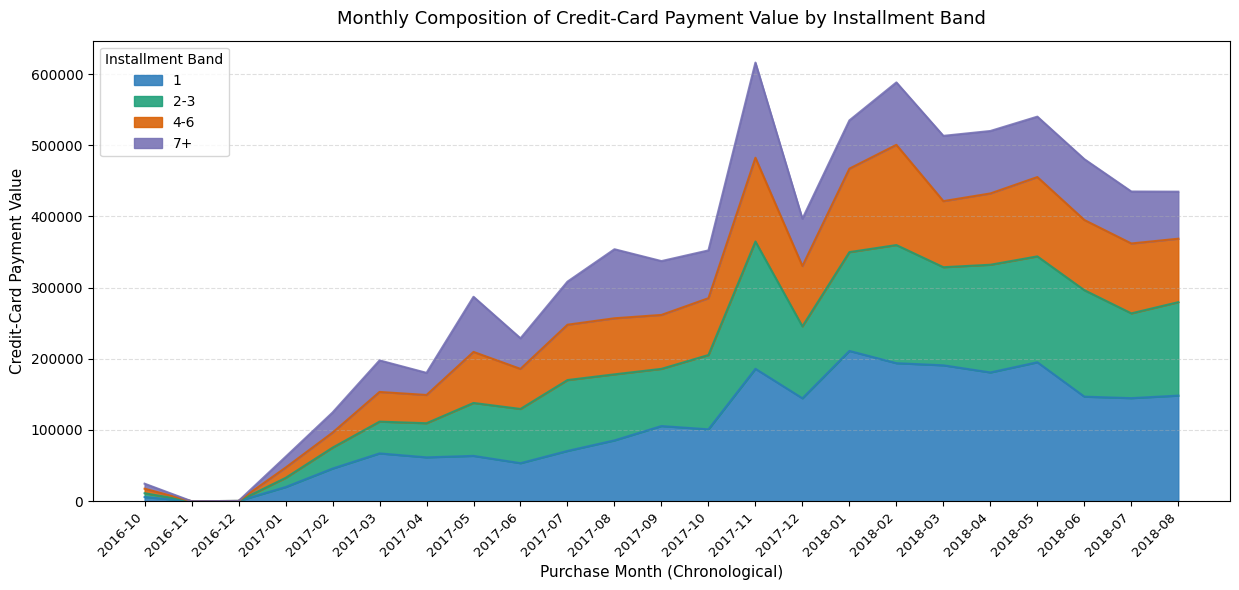

In [76]:
#16
cc_df = (
    payments.merge(
        orders[["order_id", "order_purchase_timestamp"]].dropna(
            subset=["order_purchase_timestamp"]
        ),
        on="order_id",
        how="inner",
    )
    .dropna(subset=["payment_type", "payment_installments", "payment_value"])
    .copy()
)

cc_df["payment_type_norm"] = (
    cc_df["payment_type"]
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)
cc_df = cc_df[cc_df["payment_type_norm"] == "credit_card"].copy()

cc_df["installments_num"] = pd.to_numeric(
    cc_df["payment_installments"], errors="coerce"
)
cc_df = cc_df.dropna(subset=["installments_num"]).copy()
cc_df = cc_df[cc_df["installments_num"] > 0].copy()


def assign_installment_band(val):
    if val == 1:
        return "1"
    elif 2 <= val <= 3:
        return "2-3"
    elif 4 <= val <= 6:
        return "4-6"
    return "7+"


cc_df["installment_band"] = cc_df["installments_num"].apply(assign_installment_band)
cc_df["purchase_month"] = pd.to_datetime(
    cc_df["order_purchase_timestamp"]
).dt.to_period("M")

band_order = ["1", "2-3", "4-6", "7+"]
all_months = pd.period_range(
    cc_df["purchase_month"].min(),
    cc_df["purchase_month"].max(),
    freq="M",
)

area_df = (
    cc_df.groupby(["purchase_month", "installment_band"])["payment_value"]
    .sum()
    .unstack(fill_value=0)
    .reindex(index=all_months, columns=band_order, fill_value=0)
)
area_df.index = area_df.index.astype(str)

ax = area_df.plot(
    kind="area",
    stacked=True,
    figsize=(12.5, 6),
    color=["#2b7bba", "#1b9e77", "#d95f02", "#7570b3"],
    alpha=0.88,
)
ax.set_title(
    "Monthly Composition of Credit-Card Payment Value by Installment Band",
    fontsize=13,
    pad=12,
)
ax.set_xlabel("Purchase Month (Chronological)", fontsize=11)
ax.set_ylabel("Credit-Card Payment Value", fontsize=11)
ax.set_xticks(range(len(area_df.index)))
ax.set_xticklabels(area_df.index, rotation=45, ha="right", fontsize=9.5)
ax.legend(title="Installment Band", loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

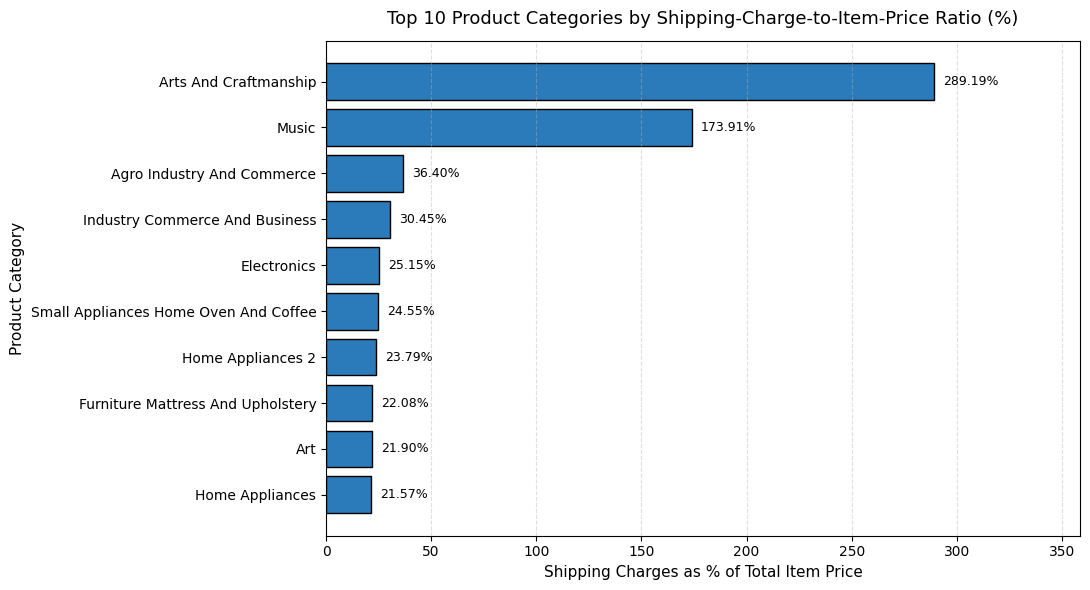

In [77]:
#17
prod_cat = products[["product_id", "product_category_name"]].copy()
prod_cat["category"] = (
    prod_cat["product_category_name"]
    .fillna("")
    .astype(str)
    .str.strip()
    .replace("", "Unknown")
)

cat_totals = (
    order_items[["product_id", "price", "shipping_charges"]]
    .merge(prod_cat[["product_id", "category"]], on="product_id", how="left")
    .assign(category=lambda d: d["category"].fillna("Unknown"))
    .groupby("category", as_index=False)
    .agg(
        total_item_price=("price", "sum"),
        total_shipping_charges=("shipping_charges", "sum"),
    )
)

cat_ratios = cat_totals[cat_totals["total_item_price"] > 0].copy()
cat_ratios["shipping_to_price_pct"] = (
    cat_ratios["total_shipping_charges"] / cat_ratios["total_item_price"]
) * 100.0

top10_ratios = (
    cat_ratios.sort_values("shipping_to_price_pct", ascending=False)
    .head(10)
    .copy()
)
top10_ratios["display_category"] = (
    top10_ratios["category"].str.replace("_", " ", regex=False).str.title()
)

plot_df = top10_ratios.iloc[::-1].reset_index(drop=True)

plt.figure(figsize=(11, 6))
bars = plt.barh(
    plot_df["display_category"],
    plot_df["shipping_to_price_pct"],
    color="#2b7bba",
    edgecolor="black",
)
max_val = plot_df["shipping_to_price_pct"].max()
plt.xlim(0, max_val * 1.24)
plt.xlabel("Shipping Charges as % of Total Item Price", fontsize=11)
plt.ylabel("Product Category", fontsize=11)
plt.title(
    "Top 10 Product Categories by Shipping-Charge-to-Item-Price Ratio (%)",
    fontsize=13,
    pad=12,
)
for bar, (_, row) in zip(bars, plot_df.iterrows()):
    plt.text(
        bar.get_width() + max_val * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{row['shipping_to_price_pct']:.2f}%",
        va="center",
        fontsize=9,
    )
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

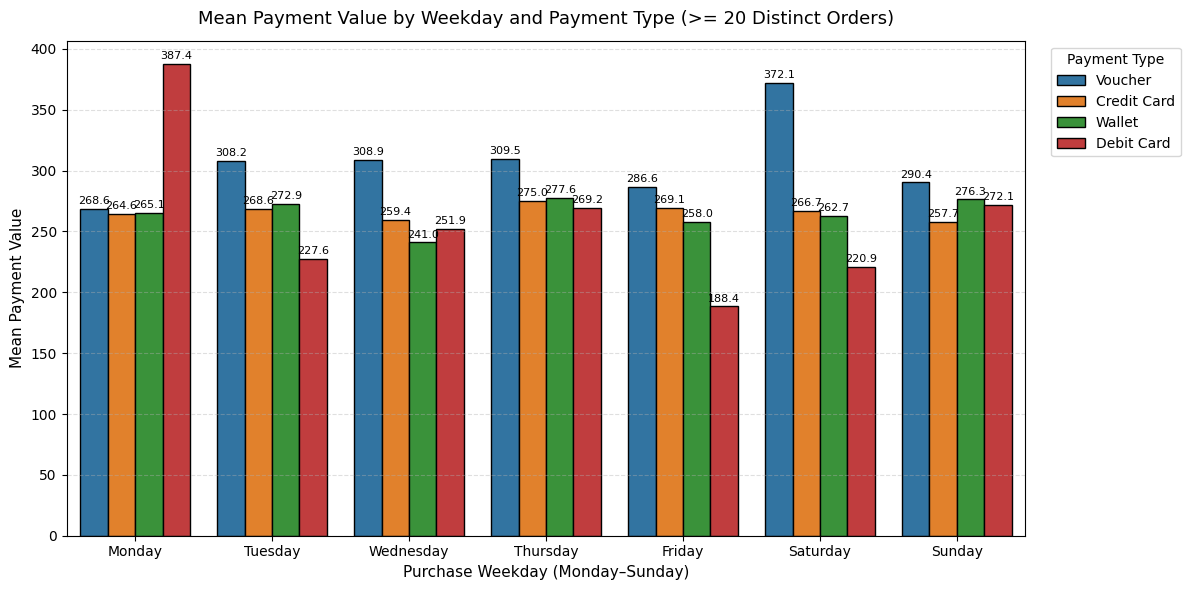

In [78]:
#18
df_pay_wd = (
    payments[["order_id", "payment_type", "payment_value"]]
    .dropna(subset=["payment_value"])
    .merge(
        orders[["order_id", "order_purchase_timestamp"]].dropna(
            subset=["order_purchase_timestamp"]
        ),
        on="order_id",
        how="inner",
    )
    .copy()
)

df_pay_wd["purchase_dt"] = pd.to_datetime(df_pay_wd["order_purchase_timestamp"])
df_pay_wd["weekday"] = df_pay_wd["purchase_dt"].dt.day_name()
df_pay_wd["payment_type_clean"] = (
    df_pay_wd["payment_type"].fillna("Unknown").str.replace("_", " ").str.title()
)

weekdays = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]

grp_summary = (
    df_pay_wd.groupby(["weekday", "payment_type_clean"], as_index=False)
    .agg(
        mean_payment_value=("payment_value", "mean"),
        distinct_orders=("order_id", "nunique"),
    )
    .query("distinct_orders >= 20")
    .copy()
)

active_weekdays = [w for w in weekdays if w in set(grp_summary["weekday"])]
payment_order = (
    grp_summary.groupby("payment_type_clean")["mean_payment_value"]
    .mean()
    .sort_values(ascending=False)
    .index.tolist()
)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=grp_summary,
    x="weekday",
    y="mean_payment_value",
    hue="payment_type_clean",
    order=active_weekdays,
    hue_order=payment_order,
    errorbar=None,
    edgecolor="black",
)
ax.set_title(
    "Mean Payment Value by Weekday and Payment Type (>= 20 Distinct Orders)",
    fontsize=13,
    pad=12,
)
ax.set_xlabel("Purchase Weekday (Monday–Sunday)", fontsize=11)
ax.set_ylabel("Mean Payment Value", fontsize=11)
plt.xticks(rotation=0, fontsize=10)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=2, fontsize=8)
plt.legend(title="Payment Type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

 order_year  total_item_price  distinct_orders  active_months            min_date            max_date    coverage_status                                              x_label
       2016           36712.0              114              2 2016-10-03 16:56:50 2016-12-23 23:16:47 Incomplete (2 mos) 2016\n(2016-10-03 to 2016-12-23)\nIncomplete (2 mos)
       2017         6209478.0            17658             12 2017-01-05 12:01:20 2017-12-31 21:10:02  Complete (12 mos)  2017\n(2017-01-05 to 2017-12-31)\nComplete (12 mos)
       2018         6865642.0            20507              9 2018-01-01 02:48:41 2018-09-03 09:06:57 Incomplete (9 mos) 2018\n(2018-01-01 to 2018-09-03)\nIncomplete (9 mos)


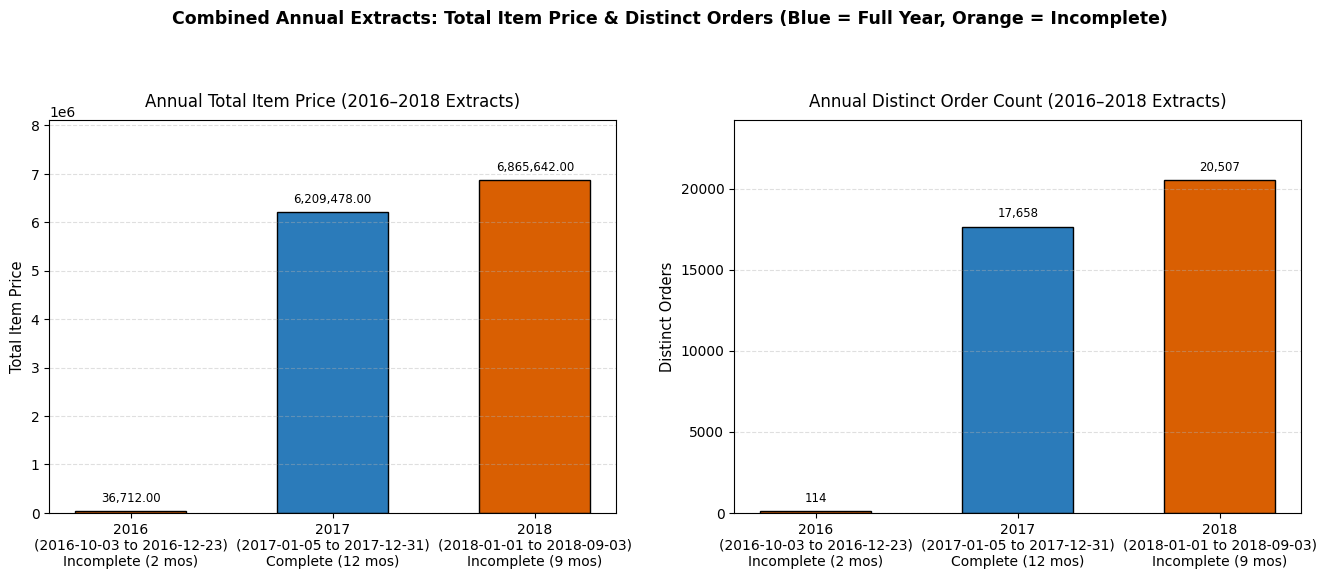

In [79]:
#19
orders_clean = orders.dropna(subset=["order_purchase_timestamp"]).copy()
orders_clean["purchase_dt"] = pd.to_datetime(orders_clean["order_purchase_timestamp"])
orders_clean["order_year"] = orders_clean["purchase_dt"].dt.year

extract_2016 = orders_clean[orders_clean["order_year"] == 2016].drop_duplicates(
    subset=["order_id"]
)
extract_2017 = orders_clean[orders_clean["order_year"] == 2017].drop_duplicates(
    subset=["order_id"]
)
extract_2018 = orders_clean[orders_clean["order_year"] == 2018].drop_duplicates(
    subset=["order_id"]
)

combined_orders = pd.concat(
    [extract_2016, extract_2017, extract_2018], ignore_index=True
).drop_duplicates(subset=["order_id"], keep="first")

order_prices = (
    order_items[["order_id", "price"]]
    .groupby("order_id", as_index=False)["price"]
    .sum()
    .rename(columns={"price": "order_item_price"})
)

combined_with_price = combined_orders.merge(
    order_prices, on="order_id", how="left"
).assign(order_item_price=lambda d: d["order_item_price"].fillna(0.0))

annual_summary = (
    combined_with_price.groupby("order_year", as_index=False)
    .agg(
        total_item_price=("order_item_price", "sum"),
        distinct_orders=("order_id", "nunique"),
        active_months=("purchase_dt", lambda s: s.dt.to_period("M").nunique()),
        min_date=("purchase_dt", "min"),
        max_date=("purchase_dt", "max"),
    )
    .sort_values("order_year")
    .reset_index(drop=True)
)

annual_summary["coverage_status"] = annual_summary.apply(
    lambda r: (
        "Complete (12 mos)"
        if int(r["active_months"]) == 12
        else f"Incomplete ({int(r['active_months'])} mos)"
    ),
    axis=1,
)
annual_summary["x_label"] = (
    annual_summary["order_year"].astype(str)
    + "\n("
    + annual_summary["min_date"].dt.strftime("%Y-%m-%d")
    + " to "
    + annual_summary["max_date"].dt.strftime("%Y-%m-%d")
    + ")\n"
    + annual_summary["coverage_status"]
)

print(annual_summary.to_string(index=False))

bar_colors = [
    "#2b7bba" if int(m) == 12 else "#d95f02"
    for m in annual_summary["active_months"]
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.8))

bars1 = ax1.bar(
    annual_summary["x_label"],
    annual_summary["total_item_price"],
    color=bar_colors,
    edgecolor="black",
    width=0.55,
)
ax1.set_title("Annual Total Item Price (2016–2018 Extracts)", fontsize=12, pad=10)
ax1.set_ylabel("Total Item Price", fontsize=10.5)
ax1.set_ylim(0, annual_summary["total_item_price"].max() * 1.18)
ax1.grid(axis="y", linestyle="--", alpha=0.4)
for b in bars1:
    ax1.text(
        b.get_x() + b.get_width() / 2,
        b.get_height() + annual_summary["total_item_price"].max() * 0.02,
        f"{b.get_height():,.2f}",
        ha="center",
        va="bottom",
        fontsize=8.5,
    )

bars2 = ax2.bar(
    annual_summary["x_label"],
    annual_summary["distinct_orders"],
    color=bar_colors,
    edgecolor="black",
    width=0.55,
)
ax2.set_title("Annual Distinct Order Count (2016–2018 Extracts)", fontsize=12, pad=10)
ax2.set_ylabel("Distinct Orders", fontsize=10.5)
ax2.set_ylim(0, annual_summary["distinct_orders"].max() * 1.18)
ax2.grid(axis="y", linestyle="--", alpha=0.4)
for b in bars2:
    ax2.text(
        b.get_x() + b.get_width() / 2,
        b.get_height() + annual_summary["distinct_orders"].max() * 0.02,
        f"{int(b.get_height()):,}",
        ha="center",
        va="bottom",
        fontsize=8.5,
    )

fig.suptitle(
    "Combined Annual Extracts: Total Item Price & Distinct Orders (Blue = Full Year, Orange = Incomplete)",
    fontsize=12.5,
    fontweight="bold",
    y=0.99,
)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

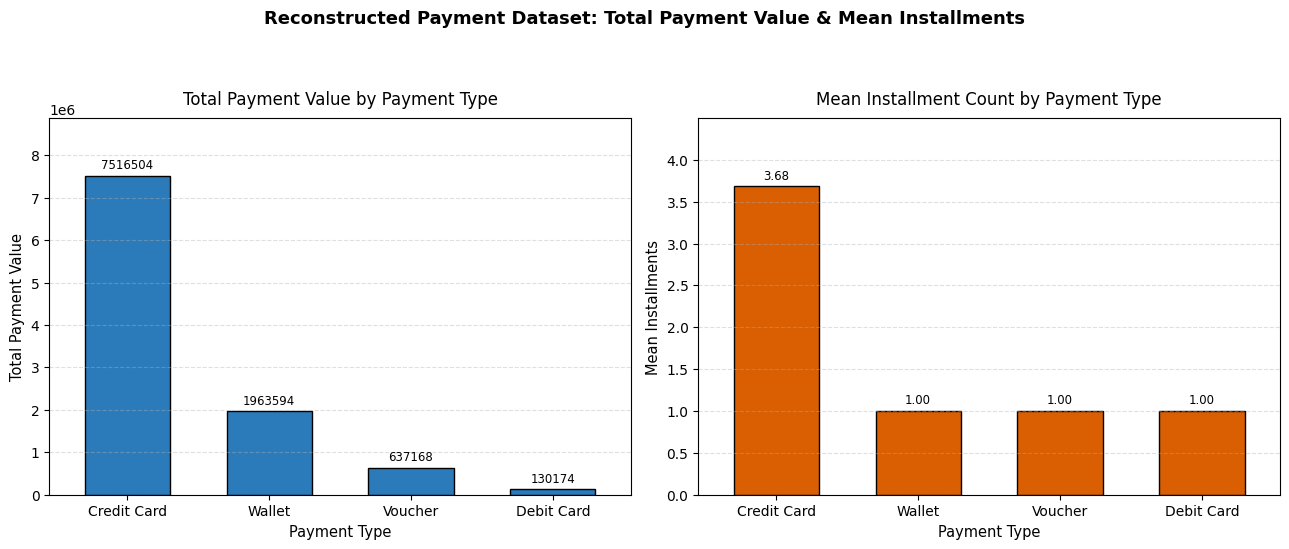

In [80]:
#20
pay_clean = payments.dropna(subset=["payment_value"]).copy()
pay_clean["payment_type_clean"] = (
    pay_clean["payment_type"].fillna("Unknown").str.replace("_", " ").str.title()
)
pay_clean["installments_num"] = pd.to_numeric(
    pay_clean["payment_installments"], errors="coerce"
)

payment_extracts = {
    ptype: grp.copy()
    for ptype, grp in pay_clean.groupby("payment_type_clean", dropna=False)
}
reconstructed_payments = pd.concat(
    payment_extracts.values(), ignore_index=True
)

type_summary = (
    reconstructed_payments.groupby("payment_type_clean", as_index=True)
    .agg(
        total_payment_value=("payment_value", "sum"),
        mean_installments=("installments_num", "mean"),
    )
    .sort_values("total_payment_value", ascending=False)
)

category_order = type_summary.index.tolist()
plot_df = type_summary.loc[category_order]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))

plot_df["total_payment_value"].plot(
    kind="bar",
    ax=ax1,
    color="#2b7bba",
    edgecolor="black",
    width=0.6,
)
ax1.set_title("Total Payment Value by Payment Type", fontsize=12, pad=10)
ax1.set_xlabel("Payment Type", fontsize=10.5)
ax1.set_ylabel("Total Payment Value", fontsize=10.5)
ax1.set_ylim(0, plot_df["total_payment_value"].max() * 1.18)
ax1.tick_params(axis="x", rotation=0)
ax1.grid(axis="y", linestyle="--", alpha=0.4)
for container in ax1.containers:
    ax1.bar_label(container, fmt="%.0f", padding=3, fontsize=8.5)

plot_df["mean_installments"].plot(
    kind="bar",
    ax=ax2,
    color="#d95f02",
    edgecolor="black",
    width=0.6,
)
ax2.set_title("Mean Installment Count by Payment Type", fontsize=12, pad=10)
ax2.set_xlabel("Payment Type", fontsize=10.5)
ax2.set_ylabel("Mean Installments", fontsize=10.5)
ax2.set_ylim(0, plot_df["mean_installments"].max() * 1.22)
ax2.tick_params(axis="x", rotation=0)
ax2.grid(axis="y", linestyle="--", alpha=0.4)
for container in ax2.containers:
    ax2.bar_label(container, fmt="{:.2f}", padding=3, fontsize=8.5)

fig.suptitle(
    "Reconstructed Payment Dataset: Total Payment Value & Mean Installments",
    fontsize=13,
    fontweight="bold",
    y=0.99,
)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()